<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
%pip install -q requests pandas seaborn scikit-learn  # [REVISED] one quiet call instead of four verbose ones

# imports
from IPython.display import Image, display
from IPython.display import HTML, Markdown
import os
import requests
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

Note: you may need to restart the kernel to use updated packages.


# **Feature Engineering – Group 2: Feature Transformation**

**Authors:** *Nora Beringer, Malte Gerboth, Haben Ghebremeskel Tekle, Janic Rüegg, Daniel Chung, Raphael Lüthy*

### Instructor review (2026-10-08)

This notebook (Group 2 – Feature Transformation) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- (iii) Fit-on-train workflow with `ColumnTransformer`, `handle_unknown` for both encoders (code + text)
- (iv) Memory comparison dense vs. sparse; diagnostics (rows per category, unseen test categories) in the accuracy experiment
- (v) Self-generated under-/overfitting figure (degree 1/2/10, train vs. test MSE); interaction terms and feature-count growth
- (vi) General sin/cos recipe for period P; amplitude/peak computed from the weights; harmonics, RBF width and `SplineTransformer` explained
- Takeaways: LabelEncoder pitfall and dummy-variable trap; two scikit-learn references

**Corrected**
- (ii) log requires x > 0 (not ≥ 0); Box–Cox (x > 0) vs. Yeo–Johnson; PowerTransformer/QuantileTransformer must be fitted on training data
- (iii) Data file loaded from the group repository if `data/` is missing
- (iv) Dummy-variable trap: singular only together with the intercept, coefficients become non-unique; distance argument made specific to one-hot
- (iv) Experiment: encoder fitted before the split (now train only), wrong comment 'weakly correlated' target, unused import

**Revised for clarity**
- (iii) Heading aligned with course term 'label encoding' + LabelEncoder/OrdinalEncoder nuance
- (iv) Alternatives list condensed to sparse output, rare-category grouping and a short outlook
- (v) Introduction with formula and practical rules; 'y = 2x + x²' heading turned into an explanation
- (vi) Interpretation of the R² values made precise

**Removed (beyond course scope)**
- Hot-linked external figure in (v) (replaced by an equivalent self-generated plot)


<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/02_Feature_Transformation.png" width="1200"/>

## Introduction

**What is it about?**
*Feature transformation* changes the representation of a feature so that a model can use it more easily. Monotonic transforms such as the logarithm or the square root compress long-tailed distributions and turn multiplicative effects into additive ones. Categorical variables must be turned into numbers, via one-hot encoding for nominal and label (ordinal) encoding for ordered categories. Polynomial features let linear models capture non-linear relationships, and periodic features such as time of day, weekday or angle are best encoded with sine/cosine pairs or radial basis functions so that "23:59" and "00:01" end up close together.

**Where is it used?**
Everywhere tabular data is modelled: prices and incomes (log transform), customer or product categories (one-hot encoding), physical models with interactions (polynomial features), and time series with daily, weekly or seasonal cycles such as energy demand, traffic or sales forecasting (cyclic encoding).

**Why is it important for Machine Learning?**
Most learners make implicit assumptions about their inputs: linear models assume linear effects, distance-based models assume meaningful distances, and no model can directly digest strings. A well-chosen transformation can turn a hard problem into an easy one, often with a simpler model. A poorly chosen one (e.g. label-encoding nominal categories or blindly one-hot encoding high-cardinality features) introduces false orderings, sparsity and the curse of dimensionality.

## (i) Why and when feature transformations make sense



**Why?**  
Feature transformations make sense when the original features do not fit the assumptions or requirements of the machine learning model.

**What do they do?**  
They reshape features to make their **distribution, scale, or relationships** more suitable for modeling.

**When?**
- **Different scales** → standardization / normalization
- **Skewed data** → log or other mathematical transformations
- **Outliers** → transformations can reduce their influence
- **Categorical data** → encode categories numerically
- **Nonlinear relationships** → transform features to make patterns easier to model

**Key idea:**  
> **Transform the features when their current representation makes it harder for the model to learn effectively.**


The following sections go through these cases one by one: skewed numerical features in (ii), categorical features in (iii) and (iv), non-linear relationships in (v), and cyclic features in (vi). We start with the most common one in practice: skewed numerical features.

## (ii) Log, square root, and monotonic transforms

**Summary:** Use the log for strongly right skewed, positive data such as income or prices, and the square root for moderately skewed data such as counts, where the log would go too far. Both are monotonic transforms, so they help linear and distance based models, but make no difference for tree based models.

### 1. Log transform

**Reason:** In long tailed features a few extreme values dominate the model. The log compresses them and turns multiplicative effects into additive ones.

**Usage:** Strictly positive, strongly right skewed data such as income, prices or web traffic. With zeros use log(1 + x) (`np.log1p`).

**In a nutshell:** x' = log(x). Equal ratios become equal distances, so the step from 10 to 100 is as large as from 100 to 1000.

**Python:** `np.log(x)`, or `np.log1p(x)` if the data contains zeros.

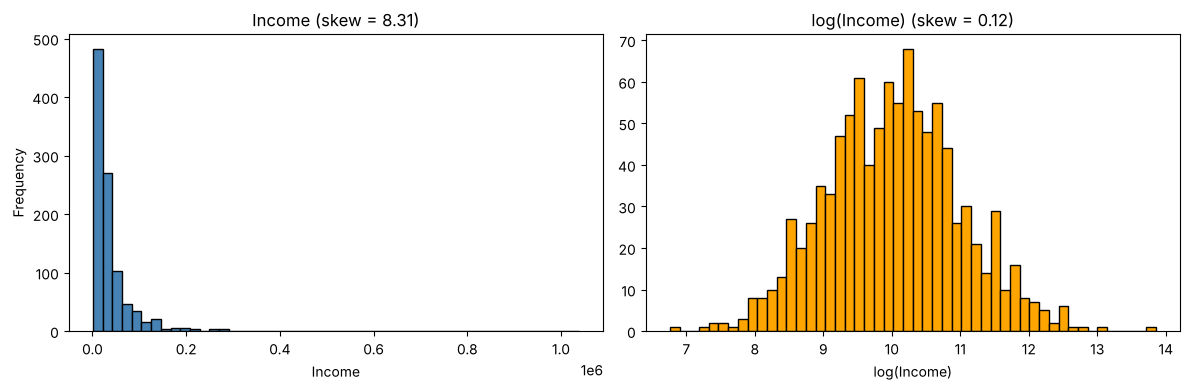

In [2]:
# Simulate right skewed income: few very high values, many low ones
np.random.seed(42)
income = np.random.lognormal(mean=10, sigma=1, size=1000)

# Log transform compresses the long tail
log_income = np.log(income)

# Histograms before and after, skewness in the title (0 = symmetric)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(income, bins=50, edgecolor='black', color='steelblue')
axes[0].set_title(f'Income (skew = {pd.Series(income).skew():.2f})')
axes[0].set_xlabel('Income')
axes[0].set_ylabel('Frequency')
axes[1].hist(log_income, bins=50, edgecolor='black', color='orange')
axes[1].set_title(f'log(Income) (skew = {pd.Series(log_income).skew():.2f})')
axes[1].set_xlabel('log(Income)')
plt.tight_layout()
plt.show()

### 2. Square root transform

**Reason:** Milder than the log. Fits moderately skewed data where the log would overcorrect.

**Usage:** Non negative, moderately right skewed data such as counts or waiting times. Zeros are allowed.

**In a nutshell:** x' = √x. Pulls in large values, but less strongly than the log.

**Python:** `np.sqrt(x)`.

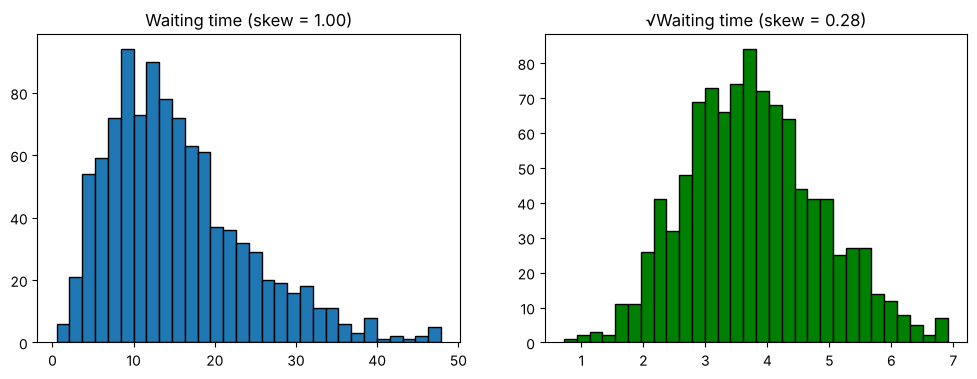

In [3]:
# Moderately right skewed data, e.g. waiting time in minutes
np.random.seed(42)
wait = np.random.gamma(shape=3, scale=5, size=1000)

# Square root transform pulls in the long right tail
sqrt_wait = np.sqrt(wait)

# Before and after, skewness in the title (0 = symmetric)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(wait, bins=30, edgecolor='black')
axes[0].set_title(f'Waiting time (skew = {pd.Series(wait).skew():.2f})')
axes[1].hist(sqrt_wait, bins=30, edgecolor='black', color='green')
axes[1].set_title(f'√Waiting time (skew = {pd.Series(sqrt_wait).skew():.2f})')
plt.show()

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *log needs x > 0 (not ≥ 0); Box–Cox/Yeo–Johnson domains and the fit-on-train rule added*

### 3. Other monotonic transforms

**Reason:** The log only works for values > 0 and the square root for values ≥ 0, and you have to pick them by hand. Other monotonic transforms also handle negative values or choose the best transform automatically.

**Usage:**
1. `np.cbrt(x)` (cube root): skewed data with negative values.
2. `np.arcsinh(x)`: behaves like log, but works with 0 and negative values.
3. `PowerTransformer()`: finds the best power automatically by maximum likelihood (target: a Gaussian-like shape) and standardises the result. Box–Cox (`method='box-cox'`) needs strictly positive data, $x^{(\lambda)} = (x^\lambda - 1)/\lambda$ for $\lambda \neq 0$ and $\ln x$ for $\lambda = 0$; Yeo–Johnson (the default) extends this to zero and negative values.
4. `QuantileTransformer()`: replaces each value by its rank and maps it to a normal or uniform distribution. Robust to outliers.

They help linear models and kNN. Trees don't need them, because the order of the values stays the same.

**Data leakage:** `np.log`, `np.sqrt` etc. are fixed formulas without parameters, so they can be applied to any split. `PowerTransformer` and `QuantileTransformer` *learn* parameters ($\lambda$, quantiles): fit them on the training set only (e.g. inside a `Pipeline`) and only `transform` the test set.

**In a nutshell:** A monotonic function never decreases (or never increases). The order of the values is kept, only the distances between them change.

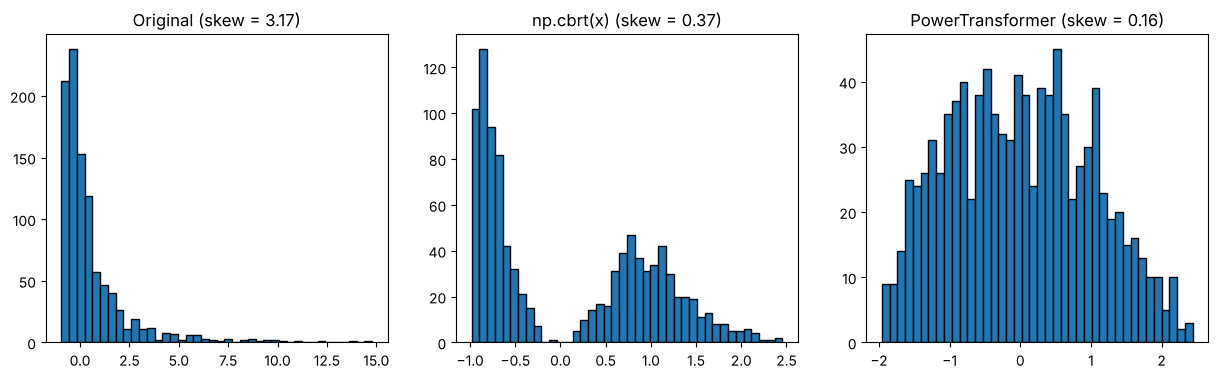

In [4]:
from sklearn.preprocessing import PowerTransformer

# Right skewed data with negative values (log would fail here)
np.random.seed(0)
x = np.random.lognormal(size=1000) - 1

# Cube root by hand vs PowerTransformer, which picks the best power itself (needs a 2D column)
data = {'Original': x,
        'np.cbrt(x)': np.cbrt(x),
        'PowerTransformer': PowerTransformer().fit_transform(x.reshape(-1, 1)).ravel()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, values) in zip(axes, data.items()):
    ax.hist(values, bins=40, edgecolor='black')
    ax.set_title(f'{name} (skew = {pd.Series(values).skew():.2f})')
plt.show()

All transforms so far assume that the feature is already a number and only change its shape. Many features, however, are categories such as a colour, a country or a clothing size. Before a model can use them, they must be encoded as numbers, which is the topic of the next section.

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *heading aligned with the course terminology; LabelEncoder vs. OrdinalEncoder nuance made explicit*

## (iii) Categorical features: nominal → one-hot encoding, ordinal → label (ordinal) encoding
Models compute with numbers, so text categories like "red" or "medium" must be encoded first. How we encode them depends on whether the categories have an order:

- **Nominal** features have no natural order (colour, country, payment method) → **one-hot encoding**
- **Ordinal** features have a clear order (clothing size: S < M < L) → **ordinal encoding**

### One-hot encoding
Create one 0/1 column per category. "red", "green" and "blue" become three indicator columns, and each row has exactly one 1, so no colour is ranked above another. The cost is one extra column per category: a high-cardinality feature such as postcodes quickly makes the data wide and sparse (see section (iv)).

### Ordinal encoding
Map the categories to integers in their real order, keeping a single column: S → 0, M → 1, L → 2. Two caveats:
- The model treats the codes as equally spaced: *S → M* counts as the same step as *M → L*, even if the real gap is different.
- **Terminology:** the course (and much literature) calls this *label encoding*. In scikit-learn, however, `LabelEncoder` is meant for the **target** `y`: it takes a 1-D array, always sorts the classes alphabetically and has no way to specify an order. For ordinal **input features** use `OrdinalEncoder` with an explicit `categories=` list.

**Rule of thumb:** if you can't say which category is "more", the feature is nominal, so use one-hot encoding.

### Example
Let's look at a small dataset of 24 Swiss hiking trips: where people went, how they got there, which snack they packed, and how hard, hungry and happy the trip was.

In [5]:
import pandas as pd

import os  # [CORRECTED] fall back to the group repository if the local data/ folder is missing
csv_path = "data/swiss_hiking_snacks.csv"
if not os.path.exists(csv_path):
    csv_path = "https://raw.githubusercontent.com/noraberinger/FeatureEngineering_HS2026/main/data/swiss_hiking_snacks.csv"
swiss_trips = pd.read_csv(csv_path)

nominal_features = ["canton", "transport", "snack"]
ordinal_orders = {
    "trail_difficulty": ["Easy", "Moderate", "Challenging"],
    "hunger": ["Not hungry", "Peckish", "Hungry", "Very hungry"],
    "satisfaction": ["Unhappy", "Neutral", "Happy", "Delighted"],
}

swiss_trips.head(3)

,trip_id,canton,transport,snack,trail_difficulty,hunger,satisfaction
0,CH001,Valais,Train,Raclette,Moderate,Very hungry,Delighted
1,CH002,Bern,PostBus,Chocolate,Easy,Peckish,Happy
2,CH003,Graubuenden,Cable car,Nusstorte,Challenging,Hungry,Neutral


Each trip has three **nominal** features (`canton`, `transport`, `snack`): there is no natural order between Valais and Ticino, or between a train and a cable car. It also has three **ordinal** features (`trail_difficulty`, `hunger`, `satisfaction`), whose categories have a clear order. So we encode the two groups differently.

#### Step 1: One-hot encode the nominal features
We start with `snack`. `OneHotEncoder` creates one 0/1 column for each snack. In every row, exactly one of these columns is `1`: the one for that trip's snack. With `handle_unknown="ignore"`, a snack the encoder has never seen (e.g. in new data at prediction time) does not raise an error; it simply gets `0` in all snack columns.

In [6]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

onehot = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
snack_onehot = pd.DataFrame(
    onehot.fit_transform(swiss_trips[["snack"]]).astype(int),
    columns=onehot.get_feature_names_out(),
    index=swiss_trips.index,
)

pd.concat([swiss_trips[["snack"]], snack_onehot], axis=1).head(6)

,snack,snack_Appenzeller cheese,snack_Chocolate,snack_Nusstorte,snack_Polenta,snack_Raclette
0,Raclette,0,0,0,0,1
1,Chocolate,0,1,0,0,0
2,Nusstorte,0,0,1,0,0
3,Appenzeller cheese,1,0,0,0,0
4,Polenta,0,0,0,1,0
5,Raclette,0,0,0,0,1


#### Step 2: Ordinal encode the ordinal features
For ordinal features we pass the order **explicitly** via `categories=`. Each feature stays a single column, and a larger number means "more difficult", "hungrier" or "happier".

In [7]:
ordinal_features = list(ordinal_orders)

display(Markdown(
    "**Ordinal features and their order:**\n\n"
    + "\n".join(f"- `{feature}`: " + " < ".join(order) for feature, order in ordinal_orders.items())
))

ordinal = OrdinalEncoder(categories=list(ordinal_orders.values()))
ordinal_encoded = pd.DataFrame(
    ordinal.fit_transform(swiss_trips[ordinal_features]).astype(int),
    columns=[f"{feature}_encoded" for feature in ordinal_features],
    index=swiss_trips.index,
)

pd.concat([swiss_trips[ordinal_features], ordinal_encoded], axis=1).head(6)

**Ordinal features and their order:**

- `trail_difficulty`: Easy < Moderate < Challenging
- `hunger`: Not hungry < Peckish < Hungry < Very hungry
- `satisfaction`: Unhappy < Neutral < Happy < Delighted

,trail_difficulty,hunger,satisfaction,trail_difficulty_encoded,hunger_encoded,satisfaction_encoded
0,Moderate,Very hungry,Delighted,1,3,3
1,Easy,Peckish,Happy,0,1,2
2,Challenging,Hungry,Neutral,2,2,1
3,Easy,Not hungry,Happy,0,0,2
4,Moderate,Hungry,Delighted,1,2,3
5,Challenging,Very hungry,Unhappy,2,3,0


#### What goes wrong if we mix them up?
Without explicit categories, `OrdinalEncoder` simply sorts the categories **alphabetically**. This causes two problems:

- **Nominal feature as integers:** the snacks get the numbers 0–4. A linear model now believes that Raclette (4) is "four times more snack" than Chocolate (1), and that the average of Appenzeller cheese (0) and Raclette (4) is a Nusstorte (2). 🧀 + 🫕 = 🥧?
- **Ordinal feature without explicit order:** alphabetically, *Challenging* < *Easy* < *Moderate*, so the trail order is scrambled.

In [8]:
lines = []
for feature in ["snack", "trail_difficulty"]:
    naive = OrdinalEncoder().fit(swiss_trips[[feature]])
    mapping = ", ".join(f"{category} → {code}" for code, category in enumerate(naive.categories_[0])) # type: ignore
    lines.append(f"- `{feature}`: {mapping}")
display(Markdown("**Naive integer encoding (alphabetical):**\n\n" + "\n".join(lines)))

**Naive integer encoding (alphabetical):**

- `snack`: Appenzeller cheese → 0, Chocolate → 1, Nusstorte → 2, Polenta → 3, Raclette → 4
- `trail_difficulty`: Challenging → 0, Easy → 1, Moderate → 2

#### Seeing it: which distances does the model "see"?
Many models (k-NN, SVMs, clustering, linear models with regularisation) work with **distances** between samples. The encoding decides these distances. Each panel below picks one category and shows how far every other category is from it after encoding:

- **Top left:** with integer encoding, the snacks form a staircase. Appenzeller cheese is 4 away from Raclette, but Polenta is only 1 away. That ranking comes from the alphabet, not from the snacks.
- **Top right:** with one-hot encoding, all bars are equal: every other snack is $\sqrt{2} \approx 1.41$ away. No snack is "closer" than another, which is exactly what *nominal* means.
- **Bottom left:** for `trail_difficulty` the integer distances *are* meaningful. Easy → Moderate is one step, Easy → Challenging is two.
- **Bottom right:** one-hot encoding flattens this order and uses more columns.

**Rule of thumb:** pick the encoding whose distances match how you think about the categories: a staircase for ordered categories, flat bars for unordered ones.

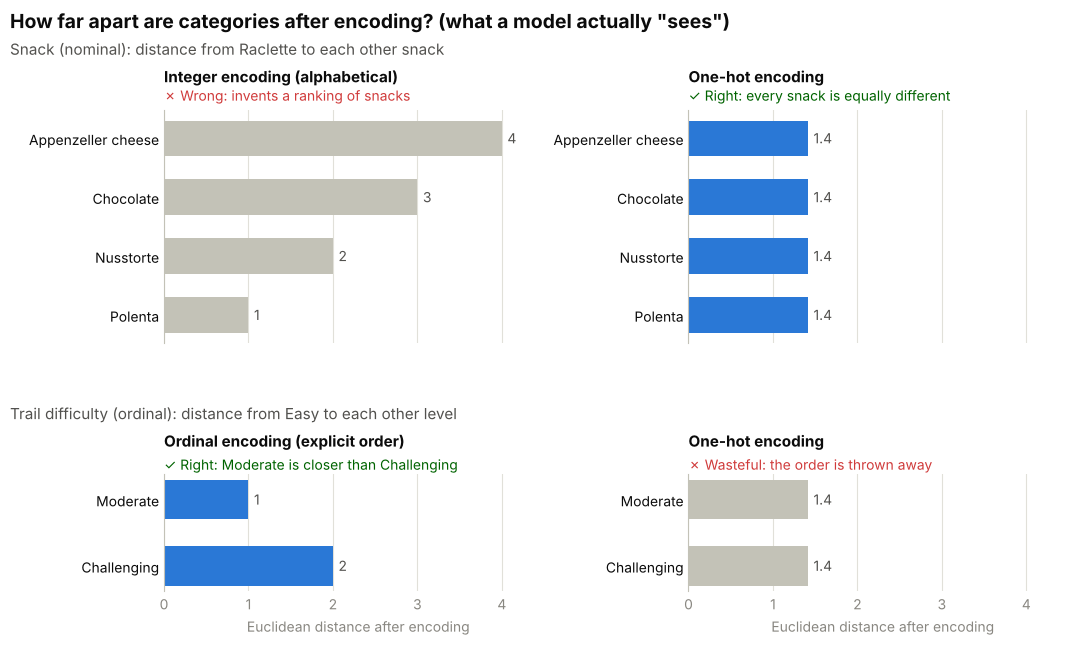

In [9]:
from sklearn.metrics import pairwise_distances


def distances_from(reference, categories, encoder):
    """Euclidean distance from `reference` to every other category after encoding."""
    encoded = encoder.fit_transform(pd.DataFrame({"x": categories}))
    dist = pd.Series(pairwise_distances(encoded)[categories.index(reference)], index=categories)
    return dist.drop(reference)


snacks = sorted(swiss_trips["snack"].unique())
difficulties = ordinal_orders["trail_difficulty"]

rows = [
    ("Snack (nominal): distance from Raclette to each other snack", [
        ("Integer encoding (alphabetical)", False, "Wrong: invents a ranking of snacks",
         distances_from("Raclette", snacks, OrdinalEncoder())),
        ("One-hot encoding", True, "Right: every snack is equally different",
         distances_from("Raclette", snacks, OneHotEncoder(sparse_output=False))),
    ]),
    ("Trail difficulty (ordinal): distance from Easy to each other level", [
        ("Ordinal encoding (explicit order)", True, "Right: Moderate is closer than Challenging",
         distances_from("Easy", difficulties, OrdinalEncoder(categories=[difficulties]))),
        ("One-hot encoding", False, "Wasteful: the order is thrown away",
         distances_from("Easy", difficulties, OneHotEncoder(sparse_output=False, categories=[difficulties]))),
    ]),
]

# colors: blue bars = good encoding, gray bars = bad encoding; verdict text in status color + icon
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BAR_GOOD, BAR_BAD = "#2a78d6", "#c3c2b7"
TEXT_GOOD, TEXT_BAD = "#006300", "#d03b3b"

xmax = max(dist.max() for _, panels in rows for *_, dist in panels) * 1.15
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [4, 2]})
fig.subplots_adjust(left=0.15, right=0.98, top=0.83, bottom=0.09, wspace=0.35, hspace=0.75)
fig.suptitle('How far apart are categories after encoding? (what a model actually "sees")',
             fontsize=14, fontweight="bold", x=0.01, y=0.985, ha="left", color=INK)

for row_axes, (row_title, panels) in zip(axes, rows):
    fig.text(0.01, row_axes[0].get_position().y1 + 0.085, row_title, fontsize=11, color=INK_2)
    for ax, (encoding, is_good, verdict, dist) in zip(row_axes, panels):
        ax.barh(dist.index, dist.values, height=0.6, color=BAR_GOOD if is_good else BAR_BAD)
        ax.bar_label(ax.containers[0], fmt="%.2g", padding=4, color=INK_2)
        ax.invert_yaxis()
        ax.set_xlim(0, xmax)
        ax.set_title(encoding, fontsize=11, fontweight="bold", loc="left", color=INK, pad=20)
        ax.text(0, 1.04, f"{'✓' if is_good else '✗'} {verdict}", transform=ax.transAxes,
                fontsize=10, color=TEXT_GOOD if is_good else TEXT_BAD)
        ax.tick_params(axis="both", length=0, labelsize=10)
        ax.tick_params(axis="x", labelcolor=MUTED)
        ax.tick_params(axis="y", labelcolor=INK)
        ax.spines[["top", "right", "bottom"]].set_visible(False)
        ax.spines["left"].set_color("#c3c2b7")
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
for ax in axes[1]:
    ax.set_xlabel("Euclidean distance after encoding", color=MUTED, fontsize=10)

plt.show()

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

#### In practice: fit the encoders on the training data only
The examples above call `fit_transform` on the whole table to keep things short. In a real workflow the encoders
*learn* the list of categories, so they must be fitted on the **training set only** (ideally inside a
`ColumnTransformer`/`Pipeline`) and then only `transform` validation/test data. New data may contain categories
that never occurred in training:

- `OneHotEncoder(handle_unknown="ignore")` → all-zero row for that feature.
- `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)` → code −1. Note that −1 is then read as
  "below the lowest level"; alternatively use `unknown_value=np.nan` and impute afterwards.

In [10]:
# [ADDED]
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

trips_train, trips_test = train_test_split(swiss_trips, test_size=0.25, random_state=0)

preprocess = ColumnTransformer([
    ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
    ("ordinal", OrdinalEncoder(categories=[ordinal_orders[f] for f in ordinal_features],
                               handle_unknown="use_encoded_value", unknown_value=-1), ordinal_features),
])
preprocess.fit(trips_train)                    # categories are learned from the training set only
print("train/test after encoding:", preprocess.transform(trips_train).shape, preprocess.transform(trips_test).shape)

# A trip with a canton, transport mode and snack that the encoder has never seen
new_trip = pd.DataFrame([{"canton": "Zurich", "transport": "Bike", "snack": "Roesti",
                          "trail_difficulty": "Easy", "hunger": "Starving", "satisfaction": "Happy"}])
encoded = pd.Series(preprocess.transform(new_trip)[0], index=preprocess.get_feature_names_out())
print("non-zero entries for the unseen trip (one-hot part is all zero, unknown hunger level → -1):\n ", encoded[encoded != 0].to_dict())

train/test after encoding: (18, 18) (6, 18)
non-zero entries for the unseen trip (one-hot part is all zero, unknown hunger level → -1):
  {'ordinal__hunger': -1.0, 'ordinal__satisfaction': 2.0}


One-hot encoding all three nominal features (6 cantons, 4 transport modes, 5 snacks) turns `3` columns into `15`, and in every row `12` of these `15` entries are 0. With only a handful of categories this is harmless. But what happens with hundreds of categories? That is the topic of the next section.

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *dummy-variable trap needs the intercept and makes coefficients non-unique (sklearn still fits); distance argument made OHE-specific; alternatives condensed to an outlook*

## (iv) Problems with one-hot encoding (sparsity, curse of dimensionality)

While One-Hot Encoding (OHE) is essential for converting nominal categorical variables into numeric values without imposing artificial order, it exhibits critical limitations when applied to **high-cardinality features** (categorical features with many unique categories, like Zip Codes, Product IDs, or Usernames).

### Core Issues

1. **High Sparsity (Data Matrix Explosion)**
   - When a feature with $K$ unique categories is one-hot encoded, it creates $K$ new binary columns.
   - For any given sample, exactly **one column will contain a `1` and $K-1$ columns will contain `0`s**.
   - As $K$ grows, the feature matrix becomes overwhelmingly populated by zeros. This wastes huge amounts of RAM and computation time unless specialized sparse matrices are used.

2. **The Curse of Dimensionality**
   - Adding dozens, hundreds, or thousands of sparse columns drastically increases the volume of the feature space.
   - **Overfitting:** Machine learning models (especially linear models, decision trees, and distance-based algorithms) become prone to finding spurious patterns in tiny subsets of data.
   - **Computational Strain:** Algorithmic training times scale linearly or quadratically with the number of features $D$.
   - **No notion of similarity:** any two different categories are exactly $\sqrt{2}$ apart (see the plot in (iii)), so $k$-NN or SVMs cannot exploit that some categories are similar; with many such columns the distances between samples become nearly uniform and less informative.

3. **Multicollinearity (The Dummy Variable Trap)**
   - Full one-hot encoding creates $K$ features whose sum is always equal to 1 for every row.
   - Together with the intercept column this is an exact linear dependency: $X^\top X$ is singular and the OLS coefficients are not unique (not interpretable). Remedies: drop one column per feature (`OneHotEncoder(drop='first')`), or use regularisation ($L_2$), which makes the solution unique. Tree models and regularised models do not need `drop='first'`.

---

### What to do about it

* **Keep the matrix sparse:** `OneHotEncoder` returns a SciPy sparse matrix by default (`sparse_output=True`); only the non-zeros are stored.
* **Group rare categories** into an `"infrequent"` bucket: `OneHotEncoder(min_frequency=...)` or `max_categories=...`.
* **Outlook (beyond this course):** frequency encoding, target encoding (needs cross-fitting to avoid target leakage), feature hashing and learned embeddings replace the $K$ columns by one or a few dense columns.

Original shape: (1000, 1)
Encoded shape:  (1000, 100)
Matrix Sparsity: 99.00% zeros
Memory dense: 800 kB, sparse CSR: 16 kB



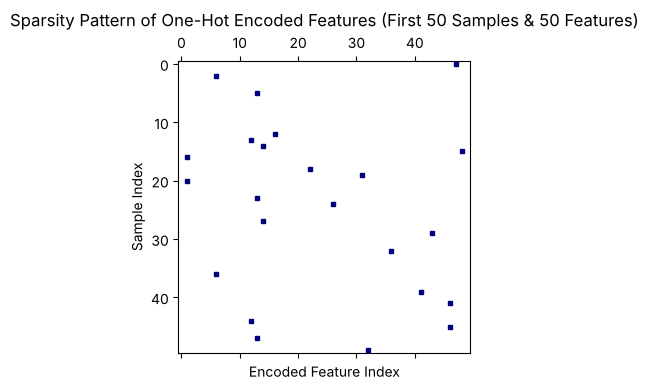

K =   2:  175.0 training rows per category,   0% of test rows have an unseen category, test accuracy = 1.00
K =  10:   35.0 training rows per category,   0% of test rows have an unseen category, test accuracy = 1.00
K =  50:    7.0 training rows per category,   0% of test rows have an unseen category, test accuracy = 1.00


K = 200:    1.8 training rows per category,  12% of test rows have an unseen category, test accuracy = 0.95


K = 500:    0.7 training rows per category,  53% of test rows have an unseen category, test accuracy = 0.74


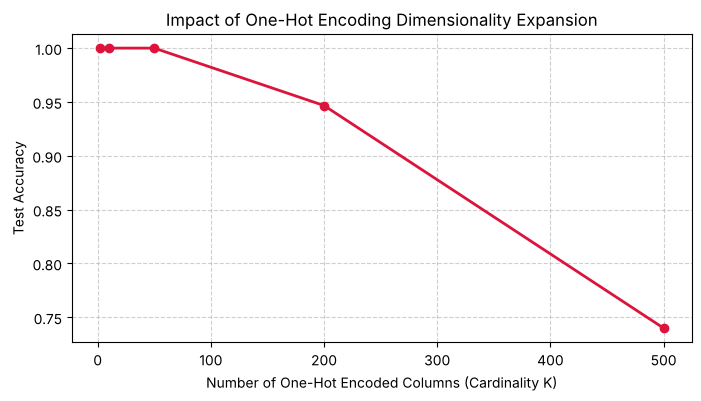

In [11]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
# [CORRECTED] unused make_classification import removed

# ---------------------------------------------------------
# 1. Visualizing Sparsity & Dimensionality Expansion
# ---------------------------------------------------------
# Create a dummy dataset with high-cardinality features
np.random.seed(42)
n_samples = 1000
high_cardinality_feature = np.random.choice([f"Category_{i}" for i in range(100)], size=n_samples)

df_demo = pd.DataFrame({"HighCard_Feature": high_cardinality_feature})

encoder = OneHotEncoder(sparse_output=False)
ohe_matrix = encoder.fit_transform(df_demo[["HighCard_Feature"]])

# Calculate Sparsity
total_elements = ohe_matrix.size
zero_elements = np.sum(ohe_matrix == 0)
sparsity = (zero_elements / total_elements) * 100

print(f"Original shape: {df_demo.shape}")
print(f"Encoded shape:  {ohe_matrix.shape}")
print(f"Matrix Sparsity: {sparsity:.2f}% zeros")
# [ADDED] memory: dense array vs. the default sparse (CSR) output
ohe_sparse = OneHotEncoder().fit_transform(df_demo[["HighCard_Feature"]])
sparse_bytes = ohe_sparse.data.nbytes + ohe_sparse.indices.nbytes + ohe_sparse.indptr.nbytes
print(f"Memory dense: {ohe_matrix.nbytes/1e3:.0f} kB, sparse CSR: {sparse_bytes/1e3:.0f} kB\n")

# Plot the Sparse Matrix
plt.figure(figsize=(10, 4))
plt.spy(ohe_matrix[:50, :50], markersize=3, color="navy")
plt.title("Sparsity Pattern of One-Hot Encoded Features (First 50 Samples & 50 Features)")
plt.xlabel("Encoded Feature Index")
plt.ylabel("Sample Index")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. Impact on Model Performance (Curse of Dimensionality)
# ---------------------------------------------------------
# Simulate model accuracy vs number of encoded categorical columns
dimensions = [2, 10, 50, 200, 500]
acc_scores = []

for d in dimensions:
    # Random categorical feature with d categories (500 samples)
    X_categories = np.random.randint(0, d, size=(500, 1))

    # [CORRECTED] the target is a deterministic function of the category (even/odd),
    # not "weakly correlated": a perfect model exists for every d, only the data per category shrinks
    y = (X_categories.ravel() % 2 == 0).astype(int)

    # [CORRECTED] split first, then fit the encoder on the training data only
    Xc_train, Xc_test, y_train, y_test = train_test_split(X_categories, y, test_size=0.3, random_state=42)
    ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    X_train = ohe.fit_transform(Xc_train)
    X_test = ohe.transform(Xc_test)

    model = LogisticRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    acc_scores.append(accuracy_score(y_test, y_pred))
    unseen = np.mean(~np.isin(Xc_test.ravel(), Xc_train.ravel()))  # [ADDED]
    print(f"K = {d:3d}: {len(y_train)/d:6.1f} training rows per category, "
          f"{unseen:4.0%} of test rows have an unseen category, test accuracy = {acc_scores[-1]:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(dimensions, acc_scores, marker='o', linewidth=2, color='crimson')
plt.title("Impact of One-Hot Encoding Dimensionality Expansion")
plt.xlabel("Number of One-Hot Encoded Columns (Cardinality K)")
plt.ylabel("Test Accuracy")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

With 100 categories, 99 % of the encoded matrix is zeros, and once there are many categories but only a few hundred training rows, test accuracy drops: each column is backed by too little data. <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> Although the target is a perfect function of the category, with $K = 500$ and only 350 training rows (< 1 row per column) about half of the test rows have a category never seen in training; for these the model can only fall back to the intercept (≈ coin flip), hence accuracy ≈ 0.75. More columns require more data: this is the curse of dimensionality in practice.

One-hot encoding adds new columns for *categorical* features. Polynomial features also add new columns, but from *numerical* features, to let a simple linear model capture curved relationships.

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *formula, interaction terms, feature-count growth and practical rules added; heading-style sentences turned into text*

## (v) Polynomial features

Transform the original dataset by adding polynomial terms of the existing features. This allows a linear model (e.g. linear regression) to learn nonlinear relationships: without polynomial features it learns a straight line, with them it can learn curves.

For one feature $x$ and degree $d$ the feature vector becomes $[x, x^2, \dots, x^d]$ and the model

$$\hat y = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d$$

is still **linear in the weights** $w_j$, so ordinary least squares (or Ridge) can be used unchanged. With $n$ input features, `PolynomialFeatures` also creates all **interaction terms** such as $x_1 x_2$. The number of output columns is $\binom{n+d}{d}$ (including the bias), which grows quickly: $n = 10$, $d = 3$ already gives 286 columns.

**Practical rules:** choose $d$ by cross-validation (usually 2–3), scale the features (powers like $x^{10}$ have huge ranges) and use regularisation (Ridge) for higher degrees.

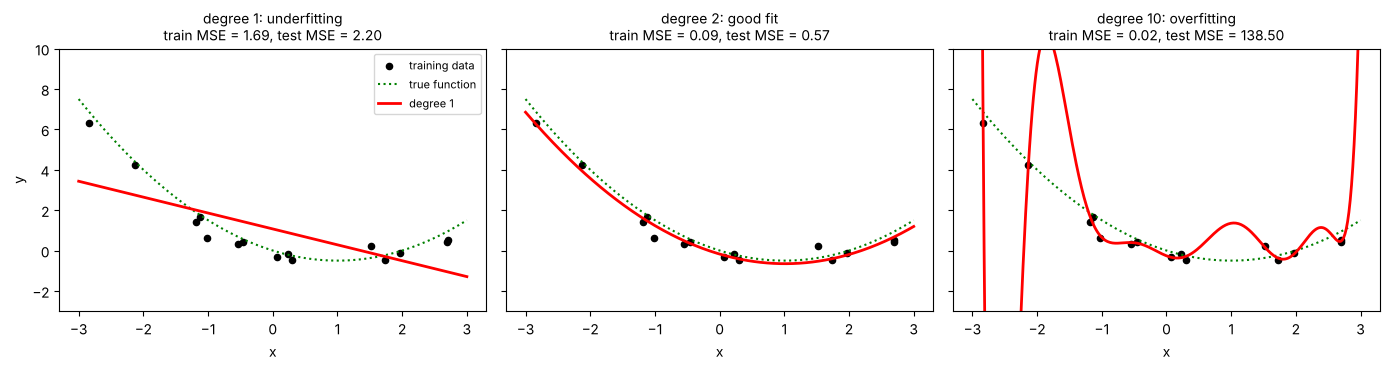

In [12]:
# [ADDED] replaces the hot-linked external figure
# Self-generated version of the classic under-/overfitting figure (replaces the hot-linked external image)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(1)
x_tr = np.sort(rng.uniform(-3, 3, 15)).reshape(-1, 1)
x_te = rng.uniform(-3, 3, 200).reshape(-1, 1)
f_true = lambda x: 0.5 * x.ravel()**2 - x.ravel()
y_tr = f_true(x_tr) + rng.normal(0, 0.8, len(x_tr))
y_te = f_true(x_te) + rng.normal(0, 0.8, len(x_te))
x_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, deg, label in zip(axes, [1, 2, 10], ["underfitting", "good fit", "overfitting"]):
    pipe = make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), LinearRegression())
    pipe.fit(x_tr, y_tr)
    ax.scatter(x_tr, y_tr, color="black", s=20, label="training data")
    ax.plot(x_plot, f_true(x_plot), "g:", label="true function")
    ax.plot(x_plot, pipe.predict(x_plot), "r-", lw=2, label=f"degree {deg}")
    ax.set_title(f"degree {deg}: {label}\ntrain MSE = {mean_squared_error(y_tr, pipe.predict(x_tr)):.2f}, "
                 f"test MSE = {mean_squared_error(y_te, pipe.predict(x_te)):.2f}", fontsize=10)
    ax.set_ylim(-3, 10); ax.set_xlabel("x")
axes[0].set_ylabel("y"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Degree 1: Too simple for a curved relationship - underfitting\
Degree 2: May capture a quadratic relationship well\
Degree 10: Could follow random noise in training data - overfitting

In [13]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Original dataset
X = np.array([[1], [2], [3], [4], [5]])
# Example target values
y = np.array([3, 8, 15, 24, 35])

# Apply polynomial transformation
poly = PolynomialFeatures(degree=2, include_bias=False)

X_poly = poly.fit_transform(X)
X_poly_y = np.column_stack((X_poly, y))

print("Polynomial Features with Target:")
print(X_poly_y)

Polynomial Features with Target:
[[ 1.  1.  3.]
 [ 2.  4.  8.]
 [ 3.  9. 15.]
 [ 4. 16. 24.]
 [ 5. 25. 35.]]


<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *bare formula heading turned into an explanation*

The targets above were generated by $y = 2x + x^2$. On the transformed features $[x, x^2]$ this is a *linear* function, so linear regression recovers $w_1 = 2$, $w_2 = 1$, $b = 0$ exactly and predicts $y(6) = 12 + 36 = 48$.

In [14]:
model = LinearRegression()
model.fit(X_poly, y)

# Predict for x = 6
X_new = poly.transform([[6]])
prediction = model.predict(X_new)

print("Predictions for x=6:")
print(prediction)
print("Learned weights for", poly.get_feature_names_out(), ":", model.coef_.round(3),  # [ADDED]
      "intercept:", round(model.intercept_, 3))

Predictions for x=6:
[48.]
Learned weights for ['x0' 'x0^2'] : [2. 1.] intercept: 0.0


In [15]:
# [ADDED]
# Two input features, degree 2: squares AND the interaction term x0*x1 are created
from math import comb
poly2 = PolynomialFeatures(degree=2, include_bias=False).fit(np.zeros((1, 2)))
print("features:", poly2.get_feature_names_out())
for n, d in [(2, 2), (10, 2), (10, 3), (50, 3)]:
    print(f"n = {n:2d} inputs, degree {d}: {comb(n + d, d) - 1:6d} columns (without bias)")

features: ['x0' 'x1' 'x0^2' 'x0 x1' 'x1^2']
n =  2 inputs, degree 2:      5 columns (without bias)
n = 10 inputs, degree 2:     65 columns (without bias)
n = 10 inputs, degree 3:    285 columns (without bias)
n = 50 inputs, degree 3:  23425 columns (without bias)


Polynomials let a linear model draw curves, but they keep rising or falling towards the edges of the data. They cannot express a pattern that **repeats**, such as the time of day, where 23:00 is followed by 0:00. For this we need periodic features.

## (vi) Periodic features: sine/cosine encoding and radial basis functions

Imagine, your goal is to predict a household's electricity consumption (in kW) from the hour of day.

- Input (feature): `hour` (0 to 23)
- Output (target): `consumption`
- Model: linear regression, deliberately simple so the effect of the encoding is easy to see

The real pattern is cyclical: consumption is lowest at night (minimum around 6:00) and highest in the evening (maximum around 18:00). At 23:00 and 0:00 it is practically the same, since only one hour separates them.

A linear regression with `hour` as the feature learns:

$$\text{consumption} = w \cdot \text{hour} + b$$

This is a straight line: consumption rises or falls monotonically across the whole day. It cannot represent consumption being high in the evening and dropping again after midnight. It also treats 23:00 and 0:00 as maximally different. The fit is poor no matter how much data you have.

The model gets two features instead:

$$\text{consumption} = a \cdot \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right) + b \cdot \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right) + c$$

The sum of a sine and a cosine component is always a **shifted cosine wave**:

$$a\sin\theta + b\cos\theta = A\cos(\theta - \varphi)$$

with amplitude $A = \sqrt{a^2 + b^2}$ and phase $\varphi = \text{atan2}(a, b)$. Through $a$ and $b$, the linear model therefore automatically learns:

- **how strongly** the daily rhythm swings (amplitude)
- **at what time** the maximum occurs (phase)

All of this happens although the model is only linear in $a$ and $b$. This is why you need **both** features: with sine alone, the position of the peak would be fixed.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> **General recipe** for a feature $x$ with period $P$ (hour: $P = 24$, weekday: $P = 7$, month: $P = 12$, angle: $P = 360°$): replace $x$ by the pair $\big(\sin(2\pi x/P),\ \cos(2\pi x/P)\big)$, i.e. a point on the unit circle.

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Synthetic data: peak at 18:00, trough at 06:00, plus noise
rng = np.random.default_rng(0)
hour = rng.integers(0, 24, size=1000)
y = 2.0 + 1.0 * np.cos(2*np.pi*(hour - 18)/24) + rng.normal(0, 0.15, size=1000)
df = pd.DataFrame({"hour": hour, "y": y})

# Two feature sets, same model
X_raw = df[["hour"]]
X_cyc = pd.DataFrame({
    "hour_sin": np.sin(2*np.pi*df["hour"]/24),
    "hour_cos": np.cos(2*np.pi*df["hour"]/24),
})

m_raw = LinearRegression().fit(X_raw, df["y"])
m_cyc = LinearRegression().fit(X_cyc, df["y"])

print(f"Raw hour : R² = {r2_score(df['y'], m_raw.predict(X_raw)):.3f}")
print(f"Sin/Cos  : R² = {r2_score(df['y'], m_cyc.predict(X_cyc)):.3f}")

# [ADDED] read amplitude and peak time from the two weights (see formula above)
a, b = m_cyc.coef_
peak_hour = (np.arctan2(a, b) * 24 / (2*np.pi)) % 24
print(f"Amplitude A = {np.hypot(a, b):.2f}, peak at {peak_hour:.1f} h")

Raw hour : R² = 0.576
Sin/Cos  : R² = 0.960
Amplitude A = 1.01, peak at 18.0 h


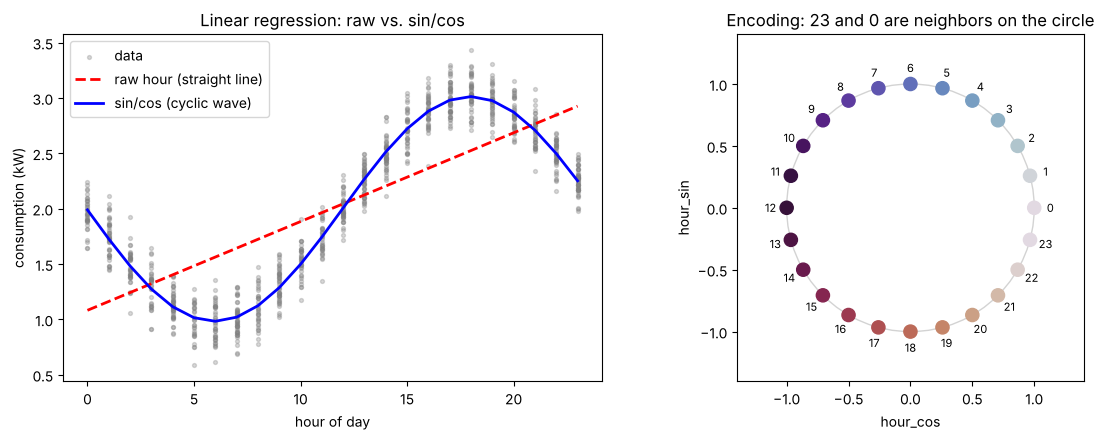

In [17]:
# Visualisation
grid = np.arange(0, 24)
G_raw = pd.DataFrame({"hour": grid})
G_cyc = pd.DataFrame({"hour_sin": np.sin(2*np.pi*grid/24),
                      "hour_cos": np.cos(2*np.pi*grid/24)})

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: fits in original hour space
ax[0].scatter(df["hour"], df["y"], s=8, alpha=0.3, color="gray", label="data")
ax[0].plot(grid, m_raw.predict(G_raw), "r--", lw=2, label="raw hour (straight line)")
ax[0].plot(grid, m_cyc.predict(G_cyc), "b-", lw=2, label="sin/cos (cyclic wave)")
ax[0].set(xlabel="hour of day", ylabel="consumption (kW)", title="Linear regression: raw vs. sin/cos")
ax[0].legend()

# Right: the encoding itself, hours on the unit circle
ax[1].add_patch(plt.Circle((0, 0), 1, fill=False, color="lightgray"))
sc = ax[1].scatter(G_cyc["hour_cos"], G_cyc["hour_sin"], c=grid, cmap="twilight", s=90, zorder=3)
for h in grid:
    ax[1].annotate(str(h), (G_cyc["hour_cos"][h]*1.13, G_cyc["hour_sin"][h]*1.13),
                   ha="center", va="center", fontsize=8)
ax[1].set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), aspect="equal",
          xlabel="hour_cos", ylabel="hour_sin",
          title="Encoding: 23 and 0 are neighbors on the circle")
plt.tight_layout()
plt.show()

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *R² values quoted precisely; amplitude/peak now actually computed in the code*

- **Raw value:** only R² ≈ 0.58. A straight line cannot capture the daily pattern (it only fits the trend between the trough at 6:00 and the peak at 18:00).
- **Sin/Cos:** R² close to the theoretical maximum, limited only by the noise. The fitted amplitude ($\approx 1.0$) and peak time ($\approx$ 18:00, printed above) match the values used to generate the data.

The model not only predicts better, it also **learns the daily rhythm in an interpretable form**.

Now imagine you have a consumption pattern with more than one peak, for example one in the morning at 8:00 and one in the evening at 18:00, a single wave is not enough. Instead of one global wave, place several localized "bumps" (Gaussians) at chosen centers $c_j$ along the 24-hour cycle. Each feature measures how close the hour is to one center:

$$\varphi_j(x) = \exp\left(-\gamma \cdot d(x, c_j)^2\right)$$

The distance $d$ must be **circular**, which is what makes the encoding periodic:

$$d(x, c) = \min\left(|x - c|,\; P - |x - c|\right), \quad P = 24$$

The linear model then learns one weight per bump, so (with enough centers) any smooth periodic shape can be approximated as a weighted sum of bumps.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> **Two alternatives compared below:** (1) *Fourier features*: add higher harmonics $\sin(2\pi k x/P), \cos(2\pi k x/P)$ for $k = 1, 2, 3, \dots$; (2) *periodic RBFs*. RBF hyperparameters are the number of centers and the width $\gamma$ ($\sigma = 1/\sqrt{2\gamma}$): too narrow → wiggly fit and overfitting, too wide → over-smoothed. scikit-learn's `SplineTransformer(extrapolation='periodic')` provides a similar, ready-made periodic basis. (The R² values below are in-sample; compare models on held-out data.)

Sin/Cos (k=1)        features= 2  R² = 0.180
Sin/Cos (k=1,2,3)    features= 6  R² = 0.945
RBF (12 centers)     features=12  R² = 0.955


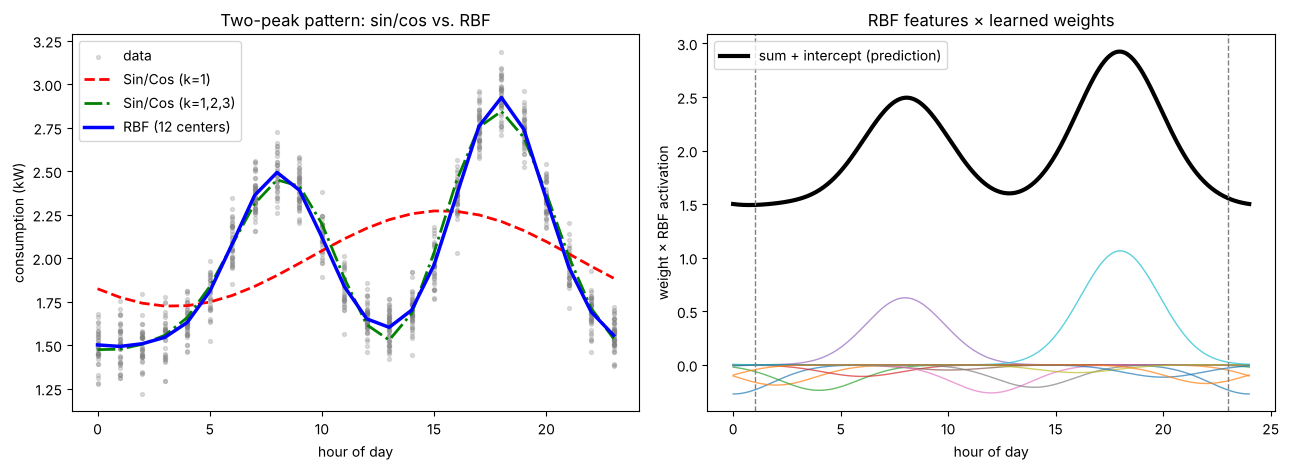

In [18]:
from sklearn.linear_model import Ridge

P = 24

def circ_dist(x, c, period=P):
    d = np.abs(np.asarray(x)[:, None] - np.asarray(c)[None, :])
    return np.minimum(d, period - d)

def gauss(x, mu, sigma):
    return np.exp(-circ_dist(x, [mu]).ravel()**2 / (2 * sigma**2))

# Synthetic data with TWO peaks: 8:00 (smaller) and 18:00 (larger)
rng = np.random.default_rng(0)
hour = rng.integers(0, 24, size=1000)
y = (1.5 + 1.0 * gauss(hour, 8, 2) + 1.4 * gauss(hour, 18, 2)
     + rng.normal(0, 0.1, size=1000))
df = pd.DataFrame({"hour": hour, "y": y})

# Feature Sets
def sincos(h, harmonics=(1,)):
    cols = {}
    for k in harmonics:
        cols[f"sin{k}"] = np.sin(2*np.pi*k*h/P)
        cols[f"cos{k}"] = np.cos(2*np.pi*k*h/P)
    return pd.DataFrame(cols)

centers = np.linspace(0, P, 12, endpoint=False)   # 0, 2, 4, ..., 22
gamma = 0.15

def rbf(h, centers=centers, gamma=gamma):
    h = np.asarray(h)
    return pd.DataFrame(np.exp(-gamma * circ_dist(h, centers)**2),
                        columns=[f"rbf_{int(c)}" for c in centers])

feature_sets = {
    "Sin/Cos (k=1)":       lambda h: sincos(h, (1,)),
    "Sin/Cos (k=1,2,3)":   lambda h: sincos(h, (1, 2, 3)),
    "RBF (12 centers)":    lambda h: rbf(h),
}

models = {}
for name, f in feature_sets.items():
    m = Ridge(alpha=1e-3).fit(f(df["hour"]), df["y"])
    models[name] = m
    print(f"{name:20s} features={f(df['hour']).shape[1]:2d}  "
          f"R² = {r2_score(df['y'], m.predict(f(df['hour']))):.3f}")

# Visualisation
grid = np.arange(0, 24)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: fits
ax[0].scatter(df["hour"], df["y"], s=8, alpha=0.25, color="gray", label="data")
styles = {"Sin/Cos (k=1)": ("r--", 2), "Sin/Cos (k=1,2,3)": ("g-.", 2), "RBF (12 centers)": ("b-", 2.5)}
for name, f in feature_sets.items():
    s, lw = styles[name]
    ax[0].plot(grid, models[name].predict(f(grid)), s, lw=lw, label=name)
ax[0].set(xlabel="hour of day", ylabel="consumption (kW)",
          title="Two-peak pattern: sin/cos vs. RBF")
ax[0].legend()

# Right: weighted basis functions
fine = np.linspace(0, 24, 400)
Phi = np.exp(-gamma * circ_dist(fine, centers)**2)
m = models["RBF (12 centers)"]
for j, c in enumerate(centers):
    ax[1].plot(fine, Phi[:, j] * m.coef_[j], lw=1, alpha=0.7)
ax[1].plot(fine, Phi @ m.coef_ + m.intercept_, "k-", lw=3, label="sum + intercept (prediction)")
for h in (23, 1):
    ax[1].axvline(h, color="gray", ls="--", lw=1)
ax[1].set(xlabel="hour of day", ylabel="weight × RBF activation",
          title="RBF features × learned weights")
ax[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

Whether we use sine/cosine pairs or RBFs, the idea is the same as in all previous sections: change the representation of the feature so that a simple model can learn the pattern. The takeaways below summarise the key points across all transformations.

## Takeaways

- **What should every ML practitioner remember?**
  - Transform a feature when its representation does not match what the model assumes: skewed values, categories as strings, curved relationships or cyclic time.
  - Monotonic transforms (log, square root, `PowerTransformer`) tame long tails. They help linear and distance-based models, but tree-based models don't need them.
  - Nominal categories → one-hot encoding; ordinal categories → `OrdinalEncoder` with an explicit `categories=` order.
  - Polynomial features let a linear model fit curves while staying linear in its weights.
  - Cyclic features (hour, weekday, month, angle) need sine **and** cosine, or periodic RBFs/splines, so that the end of the cycle meets the start.
- **What are common pitfalls?**
  - Taking the log of zero or negative values (use `np.log1p`, `np.arcsinh` or Yeo-Johnson instead).
  - Integer-encoding nominal features, or letting `OrdinalEncoder` sort ordinal categories alphabetically.
  - <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> Using `LabelEncoder` on input features: it is meant for the target `y` (1-D, alphabetical, no order). Keep `drop='first'` in mind for unregularised linear regression with an intercept (dummy-variable trap).
  - One-hot encoding high-cardinality features: sparse, wide matrices and overfitting. Group rare categories or use frequency, target or hashing encoders instead.
  - Choosing too high a polynomial degree: the feature count explodes and the model overfits.
  - Encoding a cyclic feature with sine only, which fixes the position of the peak.
  - Fitting transformers on the full dataset: fit on the training data only (e.g. inside a scikit-learn `Pipeline`) to avoid data leakage.
- **When does this technique really matter?**
  - For linear models, k-NN, SVMs and neural networks, which react to the scale, shape and distances of their inputs. Tree-based models are much less sensitive.
  - With strongly skewed real-world quantities such as prices, incomes or counts.
  - With categorical data, which every model needs as numbers.
  - With time-dependent data that has daily, weekly or seasonal cycles, such as energy demand, traffic or sales forecasting.

## References

1. https://www.geeksforgeeks.org/machine-learning/feature-transformation-techniques-in-machine-learning/ (accessed 8 October 2026)
2. Finney DJ. Was This in Your Statistics Textbook? V. Transformation of Data. Experimental Agriculture. 1989;25(2):165-175. doi:10.1017/S0014479700016665
3. https://www.analyticsvidhya.com/blog/2021/05/feature-transformations-in-data-science-a-detailed-walkthrough/ (accessed 8 October 2026)
4. https://medium.com/@adnan.mazraeh1993/polynomial-features-a-comprehensive-guide-from-basics-to-advanced-5f18c430a137 (accessed 8 October 2026)
5. Wikipedia, «Data transformation (statistics)»: https://en.wikipedia.org/wiki/Data_transformation_(statistics) (accessed 8 October 2026)
6. GeeksforGeeks, «Square Root Transformation»: https://www.geeksforgeeks.org/data-analysis/square-root-transformation/ (accessed 8 October 2026)
7. Scikit-learn Documentation – `OneHotEncoder`: Details on one-hot/dummy encoding implementations, sparse matrix outputs, and handling high-cardinality features. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html (accessed 8 October 2026)
8. Feature-engine Documentation – Categorical Encoding: Overview of high cardinality, data sparsity, rare label encoding, and alternatives to standard One-Hot Encoding. https://feature-engine.trainindata.com/en/1.8.x/user_guide/encoding/index.html (accessed 8 October 2026)
9. Zheng, A., & Casari, A. (2018). *Feature Engineering for Machine Learning: Principles and Techniques for Data Prep*. O'Reilly Media. (Chapter 3: *Building Features: Encoding Categorical Variables*).
10. ~~Figure in section (v), DeepLearning.AI community forum~~ <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> figure replaced by a self-generated plot; idea from https://global.discourse-cdn.com/dlai/original/3X/b/8/b8c30f9c214c9d7eaac0338bc9d87610c6fbef80.jpeg
11. Scikit-learn example – Time-related feature engineering (periodic features, splines): https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html

12. <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> scikit-learn User Guide – Preprocessing data (encoding categorical features, non-linear transformation, polynomial and spline features): https://scikit-learn.org/stable/modules/preprocessing.html
13. <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> scikit-learn – `LabelEncoder` (for targets) vs. `OrdinalEncoder`: https://scikit-learn.org/stable/modules/preprocessing_targets.html